QUBO Problem:

Three binary variables (have value 0 or 1): x1, x2, x3

Objective to minize : f(x) = 2.x1 + 3.x2 + 4.x3 - 5.x1.x2 - 4.x1.x3 - 6.x2.x3

QUBO formulation: min_x xT.Q.x

Upper-triangular QUBO matrix, Q = [2  -5  -4]
                                  [0   3  -6]
                                  [0   0   4]

Optimal solution: f(1,1,1) = -6 (minimum value of the function)

In [25]:
%pip install qiskit pylatexenc --quiet

In [26]:
import numpy as np
import math
import random
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import DiagonalGate

In [27]:
class GroverAdaptiveSearch:
  ''' Uses grover search repeatedly to find the minima of a given function
  '''

  def __init__(self, Q, lam=1.2, seed=42):

    self.Q = np.asarray(Q, dtype=float)

    self.n = self.Q.shape[0]  # number of binary variables
    self.N = 2 ** self.n  # search space / possible value combinations of the binary variables

    self.lam = lam
    self.rng = random.Random(seed)

    # Initial random solution
    self.best_index = self.rng.randrange(self.N)
    self.best_solution = self.decode(self.best_index)
    self.best_value = self.qubo(self.best_solution)

    self.history = []

  def decode(self, index):
    ''' Converts
    '''

    return np.array([
        (index >> i) & 1
        for i in range(self.n)
    ])

  def qubo(self, x):

    return float(x @ self.Q @ x)  # automatically converts to xT.Q.x

  def oracle(self, threshold):

    phases = []

    for i in range(self.N): # O(N) - to create the diagonal matrix for marking the phase of better solutions

      x = self.decode(i)

      cost = self.qubo(x)

      if cost < threshold:
          phases.append(-1) # phase change if gives a lower value
      else:
          phases.append(1)

    return DiagonalGate(phases)

  def diffuser(self):
    ''' Amplifies the amplitude of the solution marked by the oracle
    H-MCX-H = MCZ
    changes the phase of the marked states to -1
    '''
    qc = QuantumCircuit(self.n)

    qc.h(range(self.n))
    qc.x(range(self.n))

    qc.h(self.n - 1)
    qc.mcx(list(range(self.n - 1)), self.n - 1)
    qc.h(self.n - 1)

    qc.x(range(self.n))
    qc.h(range(self.n))

    return qc

  def grover_circuit(self, threshold, iterations):
    ''' Finds a value of function less than the current threshold
    '''

    qc = QuantumCircuit(self.n)

    # Uniform superposition
    qc.h(range(self.n))

    # Adaptive oracle
    oracle = self.oracle(threshold)

    # Diffuser
    diffuser = self.diffuser()

    for _ in range(iterations):

        qc.append(oracle, range(self.n))

        qc.compose(
            diffuser,
            inplace=True
        )

    return qc

  def measure(self, threshold, iterations):

    qc = self.grover_circuit(threshold, iterations)

    state = Statevector.from_instruction(qc)
    probabilities = state.probabilities()
    result = self.rng.choices(range(self.N), weights=probabilities, k=1)[0]

    return result

  def run(self, max_rounds=5):
    m = 1.0
    max_m = math.sqrt(self.N)

    print("Initial solution:", self.best_solution)
    print("Initial cost:", self.best_value)

    print("\n> Starting Grover Adaptive Search\n")
    for iteration in range(max_rounds):
        # Select random Grover iterations
        j = self.rng.randrange(max(1, math.ceil(m)))

        # Execute quantum search
        candidate_index = self.measure(self.best_value, j)
        candidate = self.decode(candidate_index)
        candidate_cost = self.qubo(candidate)
        improved = False

        # Update best solution
        if candidate_cost < self.best_value:
            self.best_index = candidate_index
            self.best_solution = candidate
            self.best_value = candidate_cost

            m = 1.0
            improved = True

        else:
            m = min(self.lam * m, max_m)

        current_info = {
            "Round": iteration + 1,
            "Grover_iterations": j,
            "Candidate": candidate.tolist(),
            "Candidate_cost": candidate_cost,
            "Best_solution": self.best_solution.tolist(),
            "Best_cost": self.best_value,
            "Improved": improved,
            "m": m
        }
        self.history.append(current_info)

        print(current_info)

    return self.best_solution, self.best_value

In [28]:
Q = np.array([
    [ 2, -5, -4],
    [ 0,  3, -6],
    [ 0,  0,  4]
])

gas = GroverAdaptiveSearch(Q, lam=1.2, seed=42)
solution, minimum = gas.run(max_rounds=10)

print("\n> FINAL RESULT")
print("Optimal Binary Solution:", solution)
print("Minimum QUBO Value:", minimum)

Initial solution: [1 0 0]
Initial cost: 2.0

> Starting Grover Adaptive Search

{'Round': 1, 'Grover_iterations': 0, 'Candidate': [1, 0, 1], 'Candidate_cost': 2.0, 'Best_solution': [1, 0, 0], 'Best_cost': 2.0, 'Improved': False, 'm': 1.2}
{'Round': 2, 'Grover_iterations': 0, 'Candidate': [1, 0, 0], 'Candidate_cost': 2.0, 'Best_solution': [1, 0, 0], 'Best_cost': 2.0, 'Improved': False, 'm': 1.44}
{'Round': 3, 'Grover_iterations': 0, 'Candidate': [1, 0, 1], 'Candidate_cost': 2.0, 'Best_solution': [1, 0, 0], 'Best_cost': 2.0, 'Improved': False, 'm': 1.728}
{'Round': 4, 'Grover_iterations': 0, 'Candidate': [0, 0, 1], 'Candidate_cost': 4.0, 'Best_solution': [1, 0, 0], 'Best_cost': 2.0, 'Improved': False, 'm': 2.0736}
{'Round': 5, 'Grover_iterations': 0, 'Candidate': [0, 0, 0], 'Candidate_cost': 0.0, 'Best_solution': [0, 0, 0], 'Best_cost': 0.0, 'Improved': True, 'm': 1.0}
{'Round': 6, 'Grover_iterations': 0, 'Candidate': [1, 0, 0], 'Candidate_cost': 2.0, 'Best_solution': [0, 0, 0], 'Best_co

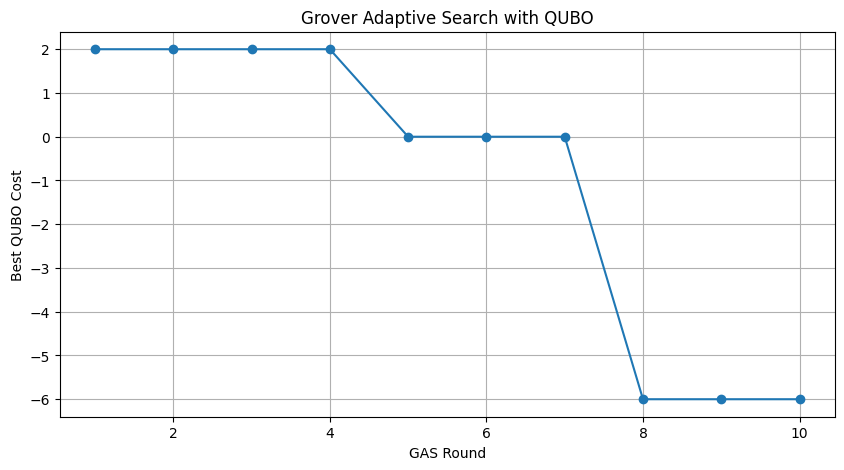

In [30]:
rounds = [item["Round"] for item in gas.history]
best_costs = [item["Best_cost"] for item in gas.history]

plt.figure(figsize=(10, 5))
plt.plot(rounds, best_costs, marker='o')
plt.xlabel("GAS Round")
plt.ylabel("Best QUBO Cost")
plt.title("Grover Adaptive Search with QUBO")
plt.grid(True)
plt.show()